# Task 5 — Original-feature EDA

Inspect the 122 supplied features, mask invalid login coordinates, and save a test-only dataset. The instructor permits unsupervised fitting on this file; no anomaly labels or offline F₃ are available.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src" / "pipeline" / "save_data.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
SRC = ROOT / "src"
RAW = SRC / "task5" / "data" / "raw"
from src.pipeline.random_seed import set_seed
SEED = set_seed()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ID = "player_id"
TARGET = "is_anomaly"

## Verify schema and leakage

In [2]:
test_raw = pd.read_csv(RAW / "test-outdate-12-11-2026.csv")
assert test_raw.shape[1] == 123
assert ID in test_raw and TARGET not in test_raw
assert test_raw[ID].notna().all() and test_raw[ID].is_unique
feature_cols = test_raw.columns.drop(ID).tolist()
assert len(feature_cols) == 122
assert all(pd.api.types.is_numeric_dtype(test_raw[c]) for c in feature_cols)
assert np.isfinite(test_raw[feature_cols].to_numpy(dtype=float)[~test_raw[feature_cols].isna().to_numpy()]).all()
print(f"{len(test_raw):,} rows, {len(feature_cols)} numeric features, no labels")
display(test_raw.head(3))

25,889 rows, 122 numeric features, no labels


,player_id,login_count_1,login_count_2,login_count_3,login_count_4,login_lat_1,login_lon_1,login_lat_2,login_lon_2,login_lat_3,...,guild_changes_1,guild_changes_2,guild_changes_3,guild_changes_4,account_age_days,behavior_stability,password_changed,vpn_usage,suspicious_login_time,mass_item_sale
0,P005807,90.311349,90.547639,85.696177,85.467099,NaN,-73.275855,39.258196,-73.608702,38.097200,...,2.0,2.0,2.0,2.0,363.872386,0.726597,0.0,0.0,0.0,0.0
1,P009995,92.522163,67.906460,113.678435,98.321423,-40.247854,-126.380420,NaN,-126.226320,-39.987100,...,0.0,0.0,0.0,1.0,1218.236865,0.774107,0.0,0.0,1.0,0.0
2,P021209,26.208497,24.837245,28.142424,31.534804,9.023819,-137.129311,8.837883,-138.033738,9.539285,...,0.0,-1.0,-1.0,1.0,502.036836,0.851379,0.0,0.0,0.0,0.0


The ID is for output matching only. `is_anomaly` is absent. No target-derived feature can be checked without labels; never include the ID as a model feature.

In [3]:
quality = pd.DataFrame({"dtype": test_raw.dtypes.astype(str),
                        "missing": test_raw.isna().sum(),
                        "missing_pct": test_raw.isna().mean().mul(100).round(2),
                        "unique": test_raw.nunique(dropna=True)})
display(quality.sort_values("missing", ascending=False).head(20))
print("Duplicate player IDs:", test_raw[ID].duplicated().sum())
print("Entirely missing feature rows:", test_raw[feature_cols].isna().all(axis=1).sum())
print("Constant/empty feature columns:", quality.loc[feature_cols].query("unique <= 1").index.tolist())

,dtype,missing,missing_pct,unique
ip_hash_entropy_4,float64,1328,5.13,24561
session_duration_std_4,float64,1324,5.11,24565
friend_adds_1,float64,1319,5.09,23376
kda_mean_4,float64,1316,5.08,24573
login_count_4,float64,1314,5.08,24575
activity_level_4,float64,1314,5.08,24575
friend_adds_3,float64,1313,5.07,23375
location_changes_2,float64,1305,5.04,24584
accuracy_std_3,float64,1305,5.04,24584
kda_std_3,float64,1302,5.03,24587


Duplicate player IDs: 0
Entirely missing feature rows: 0
Constant/empty feature columns: []


## Inspect feature groups

In [4]:
groups = sorted({c.rsplit("_", 1)[0] for c in feature_cols if c.endswith(("_1", "_2", "_3", "_4"))})
print("Four-period feature families:", len(groups))
display(pd.DataFrame({"family": groups}))
display(test_raw[feature_cols].describe(percentiles=[.01, .5, .99]).T[["min", "1%", "50%", "99%", "max"]].head(30))

Four-period feature families: 29


,family
0,accuracy_mean
1,accuracy_std
2,activity_level
3,communication_frequency
4,currency_transfers
5,device_count
6,friend_adds
7,friend_removes
8,guild_changes
9,ip_hash_entropy


,min,1%,50%,99%,max
login_count_1,8.225730,18.463891,58.086303,110.937951,118.687131
login_count_2,7.207044,17.104597,57.268171,118.475716,128.612175
login_count_3,8.081865,17.936902,57.694340,114.471892,123.566248
login_count_4,8.958444,19.180736,58.583944,107.243783,113.529203
login_lat_1,-60.670113,-58.916835,-0.205217,58.854019,61.125123
login_lon_1,-181.058839,-176.163602,2.424210,176.399692,180.526617
login_lat_2,-61.289451,-58.900091,-0.137499,58.814392,60.635566
login_lon_2,-181.249750,-176.321799,2.011649,176.487513,180.722214
login_lat_3,-98.369950,-58.963484,-0.475612,58.859716,98.537023
login_lon_3,-223.799274,-176.558970,2.251613,176.565401,213.657800


## Dataset overview

Describe the provided Test file without inventing labels. Counts, missingness and distributions help choose imputation, scaling and anomaly models. `player_id` is retained only for joining predictions.

,rows,numeric_features,periodic_feature_families,missing_cells,missing_pct,rows_with_missing_pct,duplicate_player_ids,label_available
0,25889,122,29,153872,4.87,99.75,0,False


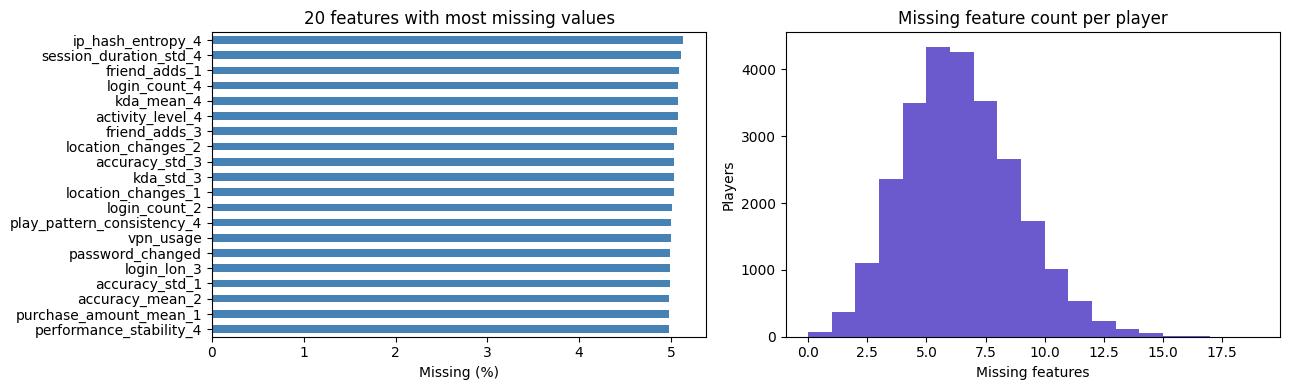

In [5]:
overview = pd.DataFrame([{
    "rows": len(test_raw), "numeric_features": len(feature_cols),
    "periodic_feature_families": len(groups),
    "missing_cells": int(test_raw[feature_cols].isna().sum().sum()),
    "missing_pct": round(100*test_raw[feature_cols].isna().to_numpy().mean(), 2),
    "rows_with_missing_pct": round(100*test_raw[feature_cols].isna().any(axis=1).mean(), 2),
    "duplicate_player_ids": int(test_raw[ID].duplicated().sum()),
    "label_available": TARGET in test_raw.columns,
}])
display(overview)
missing_by_row = test_raw[feature_cols].isna().sum(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
quality.loc[feature_cols, "missing_pct"].sort_values(ascending=False).head(20).sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("20 features with most missing values")
axes[0].set_xlabel("Missing (%)")
axes[1].hist(missing_by_row, bins=range(0, int(missing_by_row.max())+2), color="slateblue")
axes[1].set_title("Missing feature count per player")
axes[1].set_xlabel("Missing features")
axes[1].set_ylabel("Players")
fig.tight_layout()
plt.show()

## Security flags and numeric ranges

These four columns are existing input signals, **not confirmed anomaly labels**. Check their prevalence and missingness. Inspect numeric quantiles because outlier detectors can react strongly to scale and long tails.

,present,missing_pct,positive_pct_of_observed
password_changed,24596,4.99,6.27
vpn_usage,24594,5.00,15.70
suspicious_login_time,24666,4.72,4.93
mass_item_sale,24610,4.94,2.73


,min,p01,p25,median,p75,p99,max
account_age_days,180.10,195.04,523.32,846.44,1175.60,1487.21,1499.89
behavior_stability,0.20,0.38,0.76,0.82,0.89,0.95,0.95
login_count_4,8.96,19.18,38.91,58.58,78.59,107.24,113.53
device_count_4,1.00,1.00,1.00,2.00,3.00,3.00,4.00
ip_hash_entropy_4,0.00,0.30,0.42,0.55,0.67,0.79,0.80
purchase_frequency_4,0.00,0.05,1.25,2.52,3.73,5.84,24.99
currency_transfers_4,0.00,0.10,2.46,4.98,7.49,24.91,49.81
skill_rating_4,849.14,995.26,1389.51,1769.70,2148.19,2750.88,7505.10


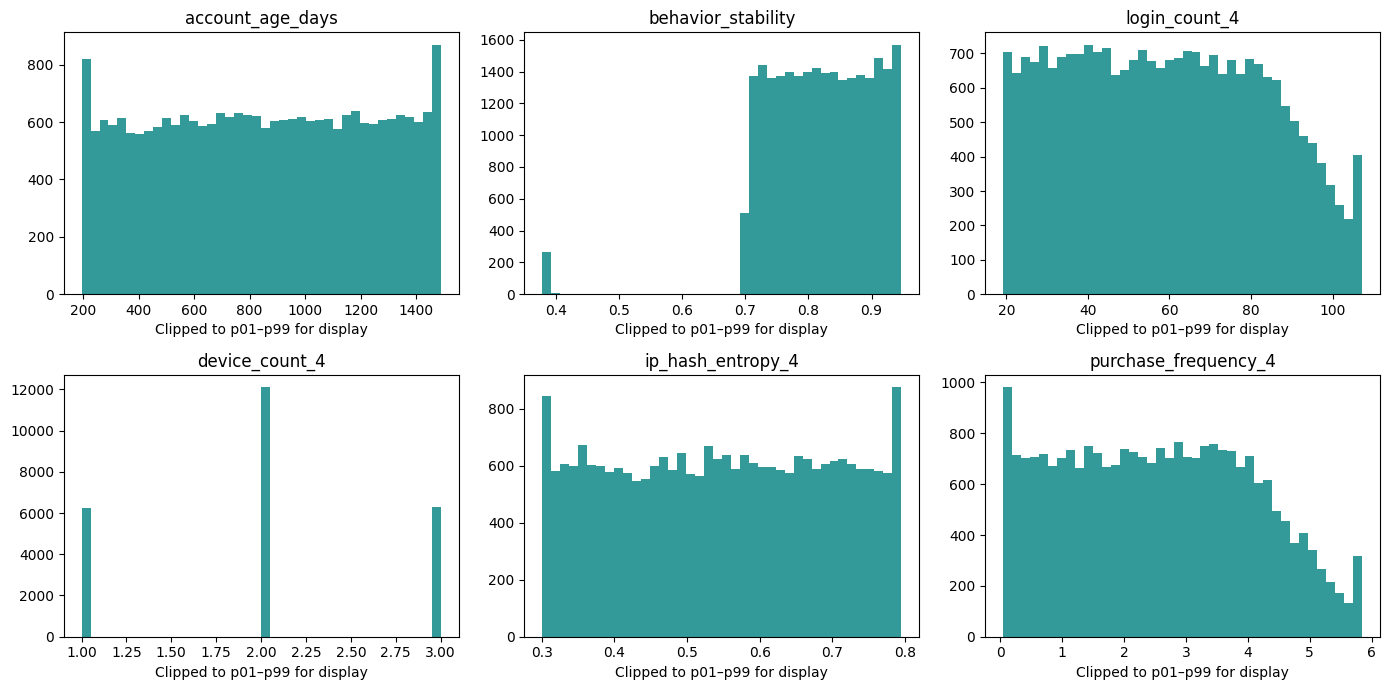

In [6]:
flag_cols = ["password_changed", "vpn_usage", "suspicious_login_time", "mass_item_sale"]
flag_table = pd.DataFrame({
    "present": test_raw[flag_cols].notna().sum(),
    "missing_pct": test_raw[flag_cols].isna().mean().mul(100),
    "positive_pct_of_observed": test_raw[flag_cols].gt(0).sum()/test_raw[flag_cols].notna().sum()*100,
}).round(2)
display(flag_table)
selected = ["account_age_days", "behavior_stability", "login_count_4", "device_count_4",
            "ip_hash_entropy_4", "purchase_frequency_4", "currency_transfers_4", "skill_rating_4"]
quantiles = test_raw[selected].quantile([0, .01, .25, .5, .75, .99, 1]).T
quantiles.columns = ["min", "p01", "p25", "median", "p75", "p99", "max"]
display(quantiles.round(2))
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for col, ax in zip(selected[:6], axes.flat):
    lo, hi = test_raw[col].quantile([.01, .99])
    ax.hist(test_raw[col].clip(lo, hi).dropna(), bins=40, color="teal", alpha=.8)
    ax.set_title(col)
    ax.set_xlabel("Clipped to p01–p99 for display")
fig.tight_layout()
plt.show()

## Coordinate quality and cleaning

,invalid_lat,invalid_lon,missing_lat,missing_lon
period,,,,
1,0,31,1203,1227
2,0,27,1275,1260
3,4,46,1259,1292
4,56,102,1286,1274


Players with at least one out-of-range coordinate: 207


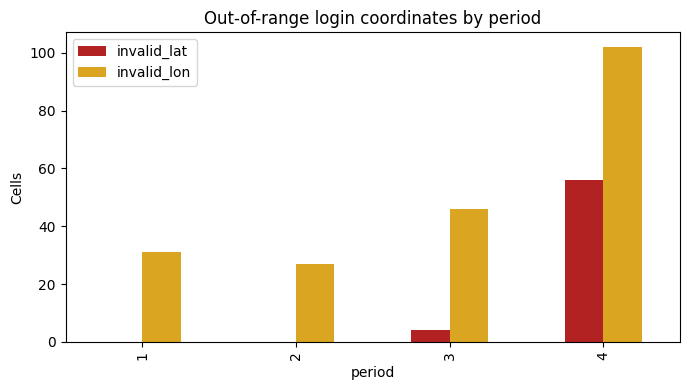

Rows retained after masking invalid coordinates: 25889


In [7]:
coord_rows = []
invalid_any = pd.Series(False, index=test_raw.index)
for period in range(1, 5):
    lat = test_raw[f"login_lat_{period}"]
    lon = test_raw[f"login_lon_{period}"]
    invalid_lat = lat.notna() & ~lat.between(-90, 90)
    invalid_lon = lon.notna() & ~lon.between(-180, 180)
    invalid_any |= invalid_lat | invalid_lon
    coord_rows.append({"period": period, "invalid_lat": int(invalid_lat.sum()),
                       "invalid_lon": int(invalid_lon.sum()),
                       "missing_lat": int(lat.isna().sum()), "missing_lon": int(lon.isna().sum())})
coord_quality = pd.DataFrame(coord_rows).set_index("period")
display(coord_quality)
print("Players with at least one out-of-range coordinate:", int(invalid_any.sum()))
coord_quality[["invalid_lat", "invalid_lon"]].plot.bar(figsize=(7, 4), color=["firebrick", "goldenrod"])
plt.title("Out-of-range login coordinates by period")
plt.ylabel("Cells")
plt.tight_layout()
plt.show()

# Keep every player ID; an invalid pair is missing, not an extreme location.
test_base = test_raw.copy()
for period in range(1, 5):
    lat_col, lon_col = f"login_lat_{period}", f"login_lon_{period}"
    invalid_pair = (test_base[lat_col].notna() & ~test_base[lat_col].between(-90, 90)) | (test_base[lon_col].notna() & ~test_base[lon_col].between(-180, 180))
    test_base.loc[invalid_pair, [lat_col, lon_col]] = np.nan
    assert test_base[lat_col].dropna().between(-90, 90).all()
    assert test_base[lon_col].dropna().between(-180, 180).all()
print("Rows retained after masking invalid coordinates:", len(test_base))


## Four-period behavior and relationships

Plot cross-player medians and interquartile ranges by period. These are population summaries; they do not prove any individual player is normal or suspicious.

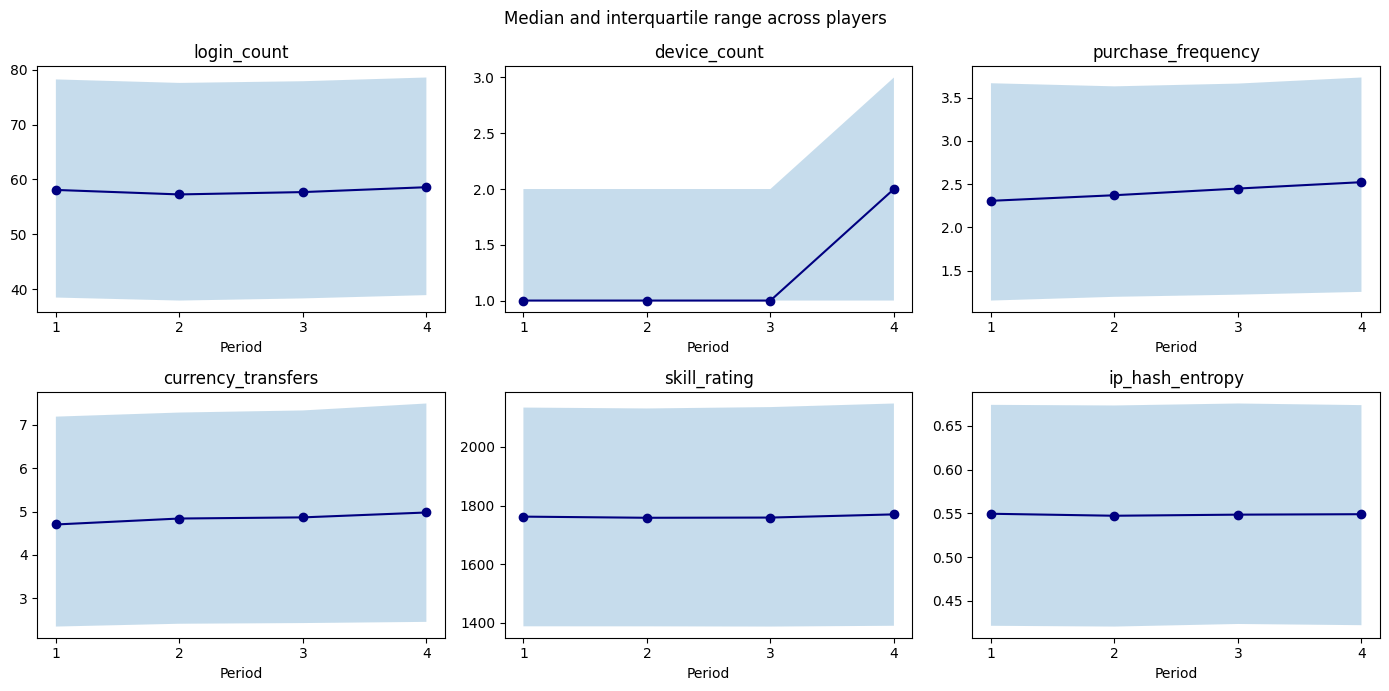

,family,period,median,p25,p75
0,login_count,1,58.09,38.47,78.24
1,login_count,2,57.27,37.91,77.60
2,login_count,3,57.69,38.31,77.91
3,login_count,4,58.58,38.91,78.59
4,device_count,1,1.00,1.00,2.00
5,device_count,2,1.00,1.00,2.00
6,device_count,3,1.00,1.00,2.00
7,device_count,4,2.00,1.00,3.00
8,purchase_frequency,1,2.31,1.15,3.67
9,purchase_frequency,2,2.37,1.20,3.63


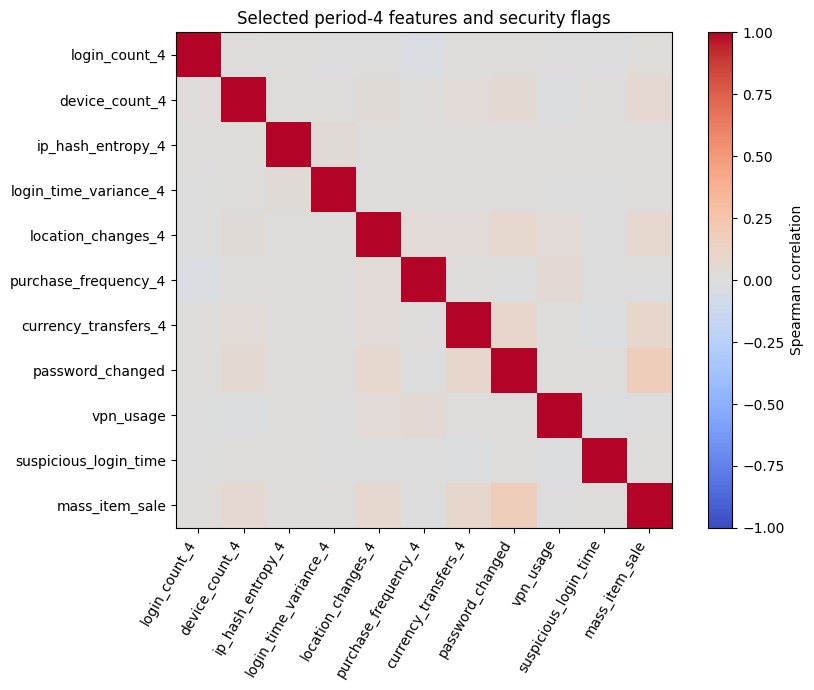

In [8]:
families_to_plot = ["login_count", "device_count", "purchase_frequency", "currency_transfers", "skill_rating", "ip_hash_entropy"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
period_rows = []
for family, ax in zip(families_to_plot, axes.flat):
    cols = [f"{family}_{period}" for period in range(1, 5)]
    med = test_raw[cols].median().to_numpy()
    p25 = test_raw[cols].quantile(.25).to_numpy()
    p75 = test_raw[cols].quantile(.75).to_numpy()
    ax.plot(range(1, 5), med, marker="o", color="navy")
    ax.fill_between(range(1, 5), p25, p75, alpha=.25)
    ax.set_xticks([1, 2, 3, 4])
    ax.set_title(family)
    ax.set_xlabel("Period")
    period_rows.extend({"family":family, "period":i, "median":med[i-1], "p25":p25[i-1], "p75":p75[i-1]} for i in range(1,5))
fig.suptitle("Median and interquartile range across players")
fig.tight_layout()
plt.show()
display(pd.DataFrame(period_rows).round(2))
relationship_cols = ["login_count_4", "device_count_4", "ip_hash_entropy_4", "login_time_variance_4",
                     "location_changes_4", "purchase_frequency_4", "currency_transfers_4",
                     "password_changed", "vpn_usage", "suspicious_login_time", "mass_item_sale"]
corr = test_raw[relationship_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
fig.colorbar(im, ax=ax, label="Spearman correlation")
ax.set_title("Selected period-4 features and security flags")
fig.tight_layout()
plt.show()

## Save original test-only artifact

In [9]:
from src.pipeline.save_data import save_data
original_info = save_data(
    task=5, name="eda_original_v1", test=test_base,
    card={"source": "task5/data/raw/test-outdate-12-11-2026.csv", "scope": "test-only; unsupervised fitting explicitly requested by user", "note": "122 original numeric features; invalid coordinate pairs masked; player_id excluded at modeling"},
)
print(original_info["splits"]["test"]["path"])

task5/data/eda/eda_original_v1-test.parquet
